# Macro Regime-Based Multi-Asset Allocation 

- Problème: static allocation breaks when macro conditions shift.
•	Hypothèse: asset behavior is regime-dependent.
•	Méthode: build economic and policy scores, classify regimes, map regimes to assets, backtest against SPY.
•	Message honnête: this is a regime-classification prototype, not yet a production-ready strategy.

## Investment question

Investment question 
Contenu:
•	Question testable: can a simple macro regime engine improve drawdown-adjusted allocation relative to buy-and-hold SPY?
•	Universe: SPY, TLT, GLD, DBC.
•	Benchmark: SPY.
•	Constraints: long-only, fully invested, daily close prices, next-period implementation.

## Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import plotly.graph_objects as go

import seaborn as sns

import yfinance as yf
from fredapi import Fred

import scipy.stats as stats
from scipy.stats import norm, probplot
from scipy import stats
from numpy.polynomial import polynomial as P

from statsmodels.tsa.stattools import adfuller, kpss

## Helper functions

### Economic and policy scores

#### Z-score

In [2]:
def zscore_fix(series, ref_start='1985-01-01', clip_val=2.5):
    ref = series.loc[ref_start:].dropna()
    mu    = ref.mean()
    sigma = ref.std(ddof=0)
    z = (series - mu) / sigma
    return z.clip(-clip_val, clip_val)

#### Momentum Score

In [3]:
def momentum_level(series, freq='monthly', lag=6, clip=2.5, ref_start='1985-01-01'):
    freq_map = {'daily': 21, 'monthly': 1, 'quarterly': 3}
    step = freq_map[freq]
    lag_n = lag * step

    delta = series - series.shift(lag_n) 
    ref = delta.loc[ref_start:].dropna()
    mu, sigma = ref.mean(), ref.std(ddof=0)

    z = (delta - mu) / sigma
    return z.clip(-clip, clip)

#### Visualize Regime evolution

In [4]:
def plot_regime_evolution(scores_df, end_date, window, econ_col="Econ_score", policy_col="Policy_score"):
    scores_df = scores_df.copy()
    scores_df.index = pd.to_datetime(scores_df.index)
    end_date = pd.to_datetime(end_date)

    sub = scores_df.loc[:end_date].tail(window)
    sub = sub.dropna(subset=[econ_col, policy_col])

    #if sub.empty:
    #    print("No available data on this window")
    #    return

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    # --- Matrix ---
    ax = axes[0]
    n = len(sub)
    colors = plt.cm.viridis(np.linspace(0, 1, n))

    ax.scatter(sub[econ_col], sub[policy_col], c=colors, s=40, zorder=2)
    ax.plot(sub[econ_col], sub[policy_col], color="gray", alpha=0.4, linewidth=1, zorder=1)

    # Last point highlighted
    ax.scatter(sub[econ_col].iloc[-1], sub[policy_col].iloc[-1],
               color="red", s=120, marker="*", zorder=3, label="Last observation")

    ax.axvline(x=0, color="black", linewidth=1)
    ax.axhline(y=0, color="black", linewidth=1)

    lim = max(3, np.abs(sub[[econ_col, policy_col]].values).max() * 1.1)
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)

    ax.set_xlabel("Econ score")
    ax.set_ylabel("Policy score")
    ax.set_title(f"Regime trajectory\n{sub.index[0].date()} → {sub.index[-1].date()} ({n} obs)")
    ax.grid(True)
    ax.legend()

    # --- Evolution on the window ---
    ax2 = axes[1]
    ax2.plot(sub.index, sub[econ_col], label="Econ score", color="tab:blue")
    ax2.plot(sub.index, sub[policy_col], label="Policy score", color="tab:orange")
    ax2.axhline(y=0, color="black", linewidth=1)
    ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
    fig.autofmt_xdate()

    ax2.set_title("Evolution of scores over time")
    ax2.set_ylabel("Score")
    ax2.legend()
    ax2.grid(True)

    plt.tight_layout()
    plt.show()




### Assets metrics

#### Import prices and compute returns / log return

In [5]:
def asset_data(ticker, start_date='1960-01-01'):
    data = yf.download(ticker, start=start_date, interval='1d')
    prices = data['Close']

    # In case of multi-index
    if hasattr(prices, 'columns'):
        prices = prices[ticker]

    returns = prices.pct_change().dropna()
    log_returns = np.log(prices / prices.shift(1)).dropna()

    return prices, returns, log_returns

#### Individual Performance

In [6]:
def performance(simple_returns, rf, mar = None):
    W = (1 + simple_returns).cumprod()
    n_years = (W.index[-1] - W.index[0]).days / 365.25

    #CAGR
    cagr = W.iloc[-1]**(1/n_years) - 1
    cagr = cagr.round(4)

    #Annualized Vol
    vol = simple_returns.std() * np.sqrt(252)
    vol = vol.round(4)

    #Sharpe ratio
    sharpe_d = (simple_returns.mean() - rf) / (simple_returns.std())
    sharpe = sharpe_d*np.sqrt(252)

    #Sortino ratio
    if mar is None:
        mar = rf
    downside = np.minimum(simple_returns - mar, 0.0)
    dd_daily = np.sqrt(np.mean(downside**2))          # downside deviation (daily)
    sortino = np.sqrt(252) * (simple_returns.mean() - mar) / dd_daily

    print('Parametric analysis of', simple_returns.name, ':\n',
          'CAGR:            ', round(cagr, 4), '%',
          '\n', 'Annualized Vol:  ', round(vol, 4), '%',
          '\n', 'Sharpe ratio:    ', round(sharpe, 4),
          '\n', "Sortino ratio:   ", round(sortino, 4), '\n')



### Regime determination

#### Plot regime perf

In [7]:
def plot_regime_compounded(regime_df, regime_name):
    fig = go.Figure()
    for asset in regime_df.columns:
        r = regime_df[asset].dropna()          # on retire les NaN avant de compounder
        nav = (1 + r).cumprod()                # capital cumulé, base 1
        
        fig.add_trace(go.Scatter(
            x=np.arange(1, len(nav) + 1),       # index séquentiel 1,2,3...
            y=nav.values,
            mode='lines',
            name=asset
        ))
    fig.update_layout(
        title=f"Cumulative growth - {regime_name}",
        xaxis_title="No of days (Sequenced, not calendar)",
        yaxis_title="%",
        template="plotly_white"
    )
    return fig

#### Performances

In [8]:
def regime_metrics(regime_df, freq=252):
    rows = {}
    for asset in regime_df.columns:
        r = regime_df[asset].dropna()
        nav = (1+r).cumprod()

        n = len(r)
        cagr = nav.iloc[-1]**(freq/n) - 1
        vol = r.std()*np.sqrt(freq)
        sharpe = r.mean()/r.std()*np.sqrt(freq) if r.std() > 0 else np.nan
        dd = nav/nav.cummax() - 1
        maxdd = dd.min()
        hit = (r > 0).mean()
        rows[asset] = dict(n_obs=n, CAGR=cagr, Vol=vol, Sharpe=sharpe, MaxDD=maxdd, HitRate=hit)
    return pd.DataFrame(rows).T

### Backtest

#### Compute the performances of a certain strategy

In [9]:
def compute_allocation_metrics(df, allocation_rules, start_date, end_date,
                                  freq=252, tc_bps=0, rf_daily=0.0, lag=1):
   
    start_date, end_date = pd.to_datetime(start_date), pd.to_datetime(end_date)

    rf_yearly = rf_daily * freq

    all_tickers = set()
    for weights in allocation_rules.values():
        all_tickers.update(weights.keys())

    ret_cols = {t: f"ret_{t}" for t in all_tickers}

    missing = set(ret_cols.values()) - set(df.columns)
    if missing:
        raise ValueError(f"Colonnes absentes de df: {missing}")

    sub = df.loc[start_date:end_date].copy()
    sub = sub.dropna(subset=list(ret_cols.values()), how="all")

    still_missing = sub[list(ret_cols.values())].isna().any()
    if still_missing.any():
        bad = still_missing[still_missing].index.tolist()
        raise ValueError(
            f"NaN résiduels (hors weekends) pour {bad} sur [{start_date.date()}, {end_date.date()}]. "
            "Restreins start_date à une période où ces actifs ont un historique complet."
        )

    if sub.empty:
        raise ValueError("no data on the time period")

    regime_exec = sub["regime"].shift(lag)

    weights_df = pd.DataFrame(0.0, index=sub.index, columns=sorted(all_tickers))
    for regime, weights in allocation_rules.items():
        mask = regime_exec == regime
        for ticker, w in weights.items():
            weights_df.loc[mask, ticker] = w

    asset_returns = sub[[ret_cols[t] for t in sorted(all_tickers)]]
    asset_returns.columns = sorted(all_tickers)

    port_ret = (weights_df * asset_returns).sum(axis=1)

    weight_changes = weights_df.diff().abs().sum(axis=1)
    weight_changes.iloc[0] = weights_df.iloc[0].abs().sum()

    port_ret_net = (port_ret - weight_changes * (tc_bps / 10000)).dropna()

    if port_ret_net.empty:
        raise ValueError("No computable returns on the time period (check lag/boundaries).")

    nav = (1 + port_ret_net).cumprod()
    n = len(port_ret_net)

    cagr = nav.iloc[-1] ** (freq / n) - 1
    ann_vol = port_ret_net.std() * np.sqrt(freq)

    sharpe_d = (port_ret_net.mean() - rf_daily) / port_ret_net.std()
    sharpe = sharpe_d * np.sqrt(freq)
    
    downside = port_ret_net[port_ret_net < 0]
    downside_vol = downside.std() * np.sqrt(freq) if len(downside) else np.nan
    sortino = (cagr - rf_yearly) / downside_vol if downside_vol else np.nan

    running_max = nav.cummax()
    max_dd = (nav / running_max - 1).min()

    turnover = weight_changes.sum() / (n / freq)
    
    result_df = pd.DataFrame({
        "regime_exec": regime_exec.loc[port_ret_net.index],
        "port_ret": port_ret_net,
        "nav": nav,
        "drawdown": nav / nav.cummax() - 1,
    })

    return {
        "CAGR": cagr, "Annualized_vol": ann_vol, "Sharpe": sharpe,
        "Sortino": sortino, "Max_DD": max_dd, "Turnover_annualized": turnover,
        "portfolio_df": result_df,
    }




#### Plot a portfolio

In [10]:
def plot_portfolio(portfolio_df, df=None, benchmark_ticker=None, title="Stratégie régime"):
    fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

    axes[0].plot(portfolio_df.index, portfolio_df["nav"], label="Strat")

    if benchmark_ticker is not None:
        if df is None:
            raise ValueError("Passe `df` pour pouvoir récupérer le benchmark.")
        bench_col = f"ret_{benchmark_ticker}"
        if bench_col not in df.columns:
            raise ValueError(f"Colonne {bench_col} absente de df.")
        bench_ret = df[bench_col].loc[portfolio_df.index]
        bench_nav = (1 + bench_ret).cumprod()
        axes[0].plot(bench_nav.index, bench_nav, label=f"Benchmark ({benchmark_ticker})", linestyle="--")

    axes[0].set_title(title)
    axes[0].set_ylabel("NAV")
    axes[0].legend()
    axes[0].grid(True)

    axes[1].fill_between(portfolio_df.index, portfolio_df["drawdown"], 0, color="red", alpha=0.4)
    axes[1].set_ylabel("Drawdown")
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()


#### Compute the return df of a certain strategy

In [11]:
def compute_strategy_returns_df(df, allocation_rules, start_date, end_date,
                                tc_bps=0, lag=1):
    
    start_date, end_date = pd.to_datetime(start_date), pd.to_datetime(end_date)

    all_tickers = set()
    for weights in allocation_rules.values():
        all_tickers.update(weights.keys())

    tickers = sorted(all_tickers)
    ret_cols = {t: f"ret_{t}" for t in all_tickers}

    missing = set(ret_cols.values()) - set(df.columns)
    if missing:
        raise ValueError(f"Colonnes absentes de df: {missing}")

    sub = df.loc[start_date:end_date].copy()
    sub = sub.dropna(subset=list(ret_cols.values()), how="all")

    still_missing = sub[list(ret_cols.values())].isna().any()
    if still_missing.any():
        bad = still_missing[still_missing].index.tolist()
        raise ValueError(
            f"NaN résiduels (hors weekends) pour {bad} sur [{start_date.date()}, {end_date.date()}]. "
            "Restreins start_date à une période où ces actifs ont un historique complet."
        )

    if sub.empty:
        raise ValueError("no data on the time period")

    regime_exec = sub["regime"].shift(lag)

    weights_df = pd.DataFrame(0.0, index=sub.index, columns=tickers)
    for regime, weights in allocation_rules.items():
        mask = regime_exec == regime
        for ticker, w in weights.items():
            weights_df.loc[mask, ticker] = w

    asset_returns = sub[[ret_cols[t] for t in tickers]].copy()
    asset_returns.columns = tickers

    gross_contrib = weights_df * asset_returns
    port_ret_gross = gross_contrib.sum(axis=1)

    weight_changes = weights_df.diff().abs().sum(axis=1)
    weight_changes.iloc[0] = weights_df.iloc[0].abs().sum()

    tc = weight_changes * (tc_bps / 10000)
    port_ret_net = port_ret_gross - tc

    ret_df = pd.DataFrame({
        "regime_exec": regime_exec,
        "port_ret_gross": port_ret_gross,
        "tc": tc,
        "port_ret_net": port_ret_net,
    }, index=sub.index)

    ret_df = pd.concat(
        [
            ret_df,
            asset_returns.add_prefix("ret_"),
            weights_df.add_prefix("w_"),
            gross_contrib.add_prefix("contrib_"),
        ],
        axis=1
    )

    ret_df = ret_df.dropna(subset=["port_ret_net"])

    if ret_df.empty:
        raise ValueError("No computable returns on the time period (check lag/boundaries).")

    return ret_df


### Generic functions

#### Plot rate

In [12]:
def plot_rate(ts_pct, name, symbol, std_lines=False):
  ts_pct_mean = np.mean(ts_pct)
  ts_pct_std = np.std(ts_pct)

  plt.figure(figsize=(15,5))
  plt.plot(ts_pct)
  plt.axhline(y=ts_pct_mean, color='red')
  plt.axhline(y=0, color='black')

  if std_lines == True:
    plt.axhline(y=ts_pct_mean-3*ts_pct_std, color='green')
    plt.axhline(y=ts_pct_mean+3*ts_pct_std, color='green')

  plt.ylabel(symbol)
  plt.title(name + "growth rate")

  plt.show()

#### Get the start date of a df or a serie

In [13]:
def start_date(data):
    if isinstance(data, pd.Series):
        print(data.name, "first obs:", data.first_valid_index())
    else:
        for col in data.columns:
            print(col, "first obs:", data[col].first_valid_index())

## Parameters

In [14]:
# Date
today = pd.to_datetime("today").normalize()

start = '1977-01-01'
regime_start = '2000-01-01'
asset_start = '2006-02-06' #DBC first obs: 2006-02-06 00:00:00

IS_end = '2019-12-30'

ASSETS = ['SPY', 'TLT', 'GLD', 'DBC']

#Risk free rate = Money market
shv_prices, shv_returns, shv_log = asset_data('SHV')
rf_daily = shv_returns.mean()
rf_annual = (1 + rf_daily) ** 252 - 1

txtregime1 = "Regime 1 = Econ + / Policy +"
txtregime2 = "Regime 2 = Econ + / Policy -"
txtregime3 = "Regime 3 = Econ - / Policy +"    
txtregime4 = "Regime 4 = Econ - / Policy -"

#backtest common parameters
tc = 10 #bps


[*********************100%***********************]  1 of 1 completed


# Macro inputs and score construction

The framework summarizes the macroeconomic environment along two dimensions:

- **Economic conditions:** unemployment, industrial production growth, and corporate earnings growth.
- **Monetary-policy conditions:** the 2-year U.S. Treasury yield and CPI inflation.

Each variable contributes through three steps:

1. **Standardized level score**: measures whether the current observation is high or low relative to its historical reference distribution.
2. **Standardized momentum score**: measures the recent direction of change of the variable.
3. **Composite variable score**: average of the level score and the momentum score. Unemployment, interest rates, and inflation are multiplied by -1 so that a higher score always corresponds to a more supportive macroeconomic environment.

| Variable | Proxy | Transformation | Sign | Role |
|---|---|---|---:|---|
| Unemployment | U.S. unemployment rate (`UNRATE`) | Raw level, plus standardized 12-month momentum | - | Economic conditions |
| Industrial production growth | Industrial Production Index (`INDPRO`) | Year-on-year growth rate, then level and momentum scoring | + | Economic conditions |
| Corporate earnings growth | Corporate profits after tax (`CP`) | Inflation-adjusted year-on-year growth, then level and momentum scoring | + | Economic conditions |
| 2Y Treasury yield | 2-year U.S. Treasury yield (`DGS2`) | Yield level, plus recent momentum; level standardization anchored to the post-2008 period | - | Monetary-policy conditions |
| CPI inflation | Consumer Price Index (`CPIAUCSL`) | Year-on-year inflation rate, then level and momentum scoring | - | Monetary-policy conditions |

The variable-level scores are then aggregated with equal weights into two composite indicators:

- **Economic Score** = average of unemployment score, growth score, and earnings score.
- **Policy Score** = average of interest-rate score and inflation score. 

These two composite scores are then used to assign each date to one of four macroeconomic regimes.


## Download and transform macro series 

In [15]:
fred = Fred(api_key="3090204fcf3ff8a14d19d60f4ea8ac31")

daily_index = pd.date_range(start=start, end=pd.Timestamp.today(), freq='B')
df = pd.DataFrame(index=daily_index) 

u = fred.get_series("UNRATE", observation_start = start)
growth = fred.get_series("INDPRO", observation_start = start)
earnings = fred.get_series("CP", observation_start = start)
rates = fred.get_series("DGS2", observation_start = start)
i_lvl = fred.get_series("CPIAUCSL", observation_start = start)

u = u.ffill() #Nan nov25
i_lvl = i_lvl.ffill() #Nan nov25, ffill before to apply to earnings

growth_yoy = growth.pct_change(fill_method=None, periods=12) * 100


earnings_m = earnings.resample('MS').ffill()
earnings_real = (earnings_m / i_lvl)*100
earnings_yoy = earnings_real.pct_change(12).dropna()*100

rates = rates.ffill() #Nan Holidays
 
i = i_lvl.pct_change(fill_method=None).dropna()*100
i_yoy  = i_lvl.pct_change(fill_method=None, periods=12) * 100

df['u'] = u.reindex(df.index, method='ffill')
df['growth'] = growth_yoy.reindex(df.index, method='ffill')
df['earnings'] = earnings_yoy.reindex(df.index, method='ffill')
df['IR'] = rates.reindex(df.index, method='ffill')
df['i'] = i_yoy.reindex(df.index, method='ffill')

df = df.loc['1978-01-01':today]

cols = ['u', 'growth', 'earnings', 'IR', 'i']

df.tail()

,u,growth,earnings,IR,i
2026-10-20,4.2,2.245151,21.998223,4.79,3.717251
2026-10-21,4.2,2.245151,21.998223,4.81,3.717251
2026-10-22,4.2,2.245151,21.998223,4.65,3.717251
2026-10-23,4.2,2.245151,21.998223,4.65,3.717251
2026-10-26,4.2,2.245151,21.998223,4.65,3.717251


## Build economic and policy scores

### Level score (z-score) of each variables

In [16]:
for col in cols:
    df[f'{col}_z'] = zscore_fix(df[col])

df['u_z'] = df['u_z'] * -1
df['IR_z'] = df['IR_z'] * -1
df['i_z'] = df['i_z'] * -1

### Momentum score of each variables

In [17]:
df['u_mom'] = momentum_level(df['u']) * -1
df['growth_mom'] = momentum_level(df['growth'])
df['earnings_mom'] = momentum_level(df['earnings'])
df['IR_mom'] = momentum_level(df['IR'], freq='daily') * -1
df['i_mom'] = momentum_level(df['i']) * -1

### Composite score of each variables

In [18]:
for col in cols:
    df[f'{col}_score'] = (df[f'{col}_z'] + df[f'{col}_mom'])/2

### Economic & Policy scores

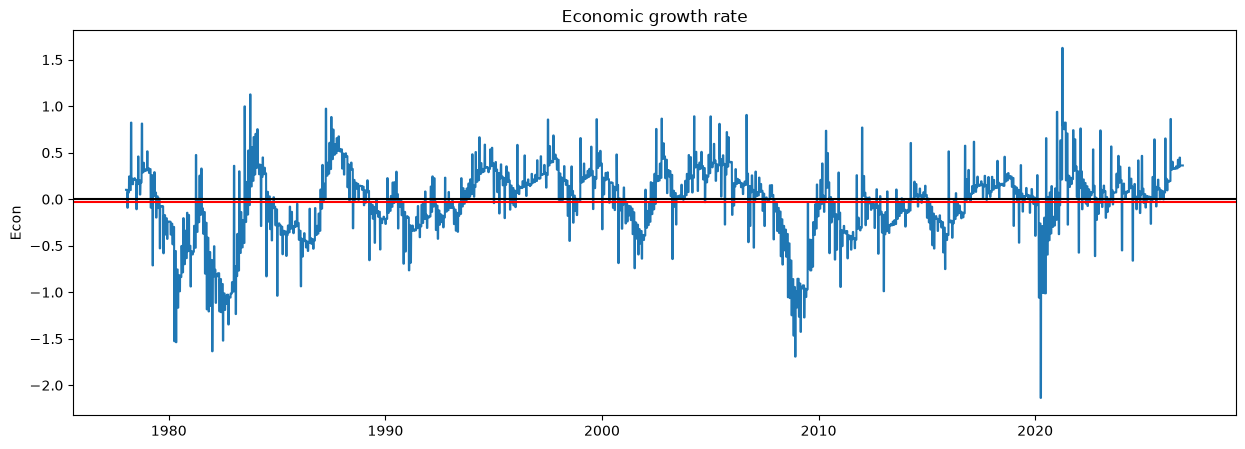

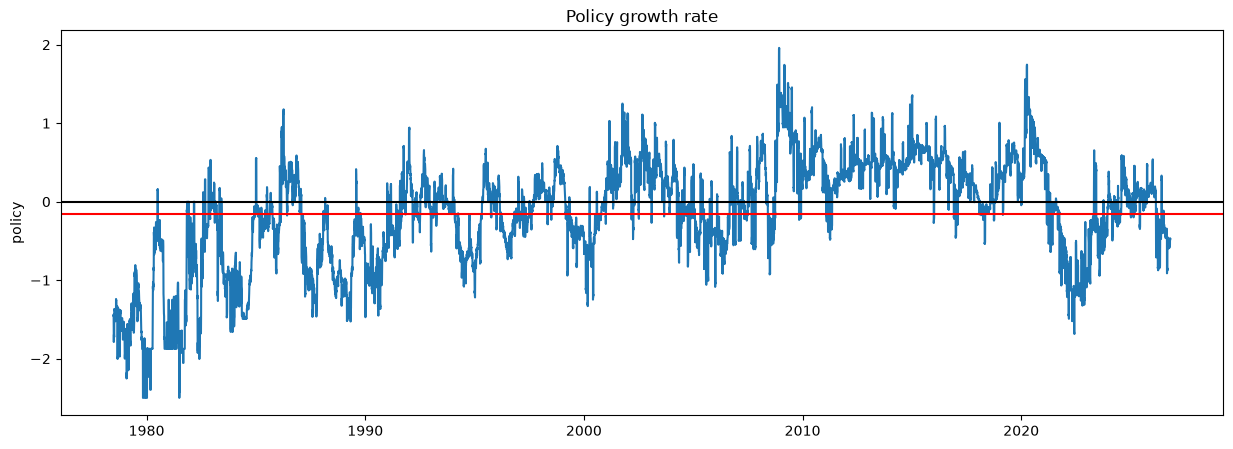

In [19]:
df['Econ_score'] = (df['u_score'] + df['growth_score'] + df['earnings_score'])/3
df['Policy_score'] = (df['IR_score'] + df['i_score'])/2

scores = df[['Econ_score', 'Policy_score']]

plot_rate(df['Econ_score'], name='Economic ', symbol='Econ', std_lines=False)
plot_rate(df['Policy_score'], name='Policy ', symbol='policy', std_lines=False)

## Compute Regimes

Regime 1 = Econ + / Policy +

Regime 2 = Econ + / Policy -

Regime 3 = Econ - / Policy +

Regime 4 = Econ - / Policy -

In [20]:
threshold = 0

df['regime'] = np.select(
    [
        (df['Econ_score'] > threshold) & (df['Policy_score'] > -threshold),
        (df['Econ_score'] > threshold) & (df['Policy_score'] <= -threshold),
        (df['Econ_score'] <= threshold) & (df['Policy_score'] > -threshold),
        (df['Econ_score'] <= threshold) & (df['Policy_score'] <= -threshold),
    ],
    [1, 2, 3, 4],
    default=0)

df = df[regime_start:]

### Regime metrics and behaviors

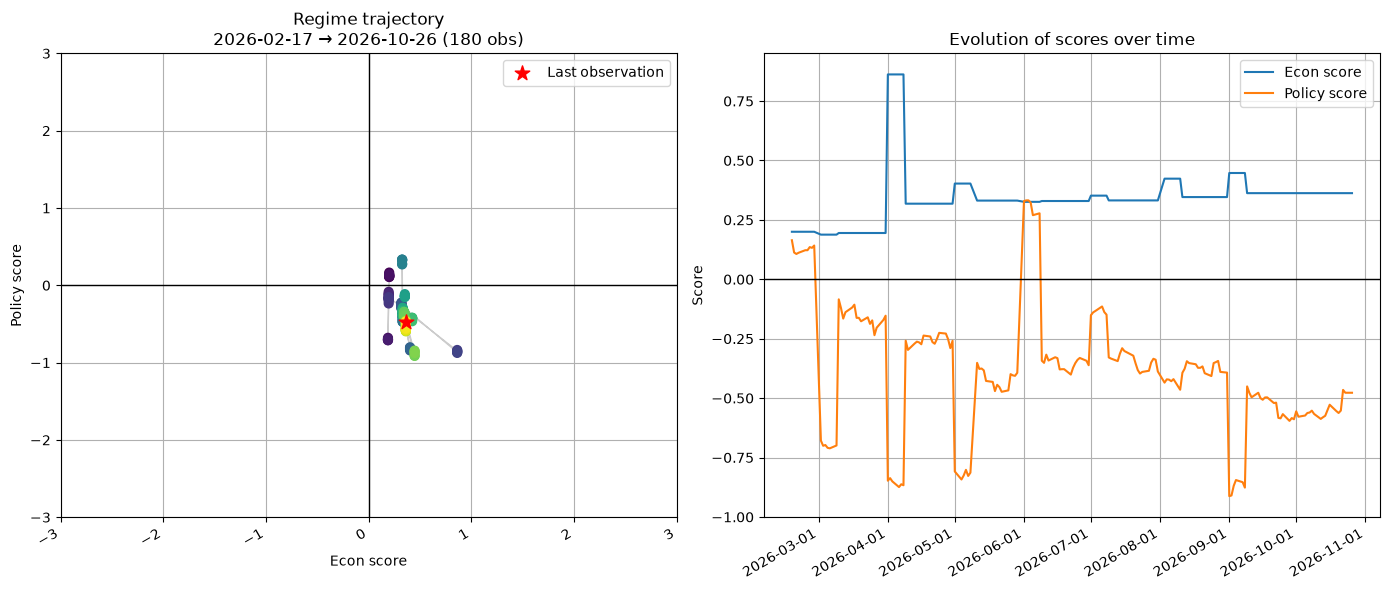

In [21]:
plot_regime_evolution(
    df,
    end_date=df.index[-1],
    window=180)


In [22]:
print("Number of observations in each regime:")
print(f"Regime 1: {(df['regime'] == 1).sum()}")
print(f"Regime 2: {(df['regime'] == 2).sum()}")
print(f"Regime 3: {(df['regime'] == 3).sum()}")
print(f"Regime 4: {(df['regime'] == 4).sum()}")

Number of observations in each regime:
Regime 1: 2015
Regime 2: 1970
Regime 3: 2590
Regime 4: 421


# Assets

## Download Assets prices and compute returns 

In [23]:
SPY_prices, SPY_returns, SPY_log = asset_data('SPY')
TLT_prices, TLT_returns, TLT_log = asset_data('TLT')
GLD_prices, GLD_returns, GLD_log = asset_data('GLD')
DBC_prices, DBC_returns, DBC_log = asset_data('DBC')

prices_df = pd.DataFrame({
    'SPY': SPY_prices,
    'TLT': TLT_prices,
    'GLD': GLD_prices,
    'DBC': DBC_prices
})

returns_df = pd.DataFrame({
    'SPY': SPY_returns,
    'TLT': TLT_returns,
    'GLD': GLD_returns,
    'DBC': DBC_returns
})

log_df = pd.DataFrame({
    'SPY': SPY_log,
    'TLT': TLT_log,
    'GLD': GLD_log,
    'DBC': DBC_log
})

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


### Plot assets prices since 2006-02-06
As DBC doesn't provide data before this date.

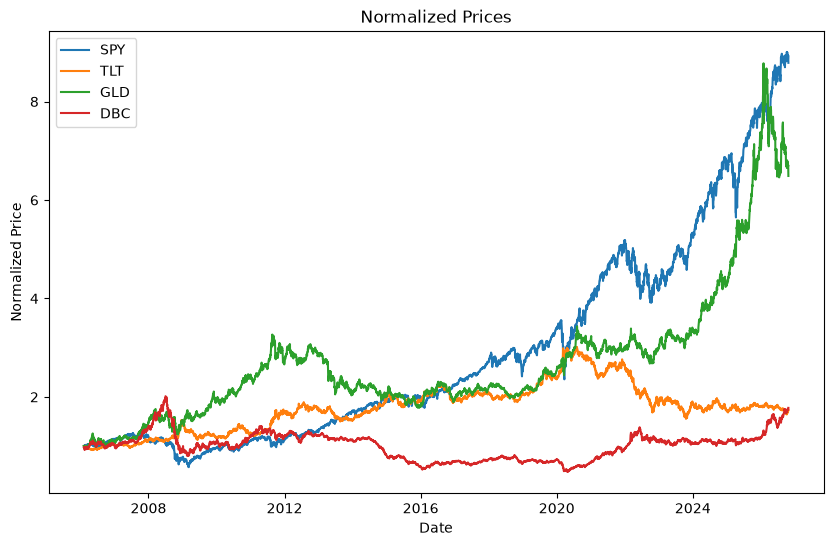

In [24]:
returns_df2 = returns_df[asset_start:]
normalized_df = returns_df2.add(1).cumprod()

plt.figure(figsize=(10, 6))
for asset in ASSETS:
    plt.plot(normalized_df.index, normalized_df[asset], label=asset)
plt.title('Normalized Prices')
plt.xlabel('Date')
plt.ylabel('Normalized Price')
plt.legend()

## Individual performance

In [25]:
for asset in ASSETS:
    returns = returns_df[asset]
    performance(returns, rf_daily)


Parametric analysis of SPY :
 CAGR:             0.1078 % 
 Annualized Vol:   0.1852 % 
 Sharpe ratio:     0.5596 
 Sortino ratio:    0.7936 

Parametric analysis of TLT :
 CAGR:             0.025 % 
 Annualized Vol:   0.1425 % 
 Sharpe ratio:     0.1998 
 Sortino ratio:    0.2841 

Parametric analysis of GLD :
 CAGR:             0.0646 % 
 Annualized Vol:   0.1827 % 
 Sharpe ratio:     0.5319 
 Sortino ratio:    0.7483 

Parametric analysis of DBC :
 CAGR:             0.0172 % 
 Annualized Vol:   0.193 % 
 Sharpe ratio:     0.1578 
 Sortino ratio:    0.217 



# Allocation determination

## Performance in regimes

Regime 1 = Econ + / Policy +

Regime 2 = Econ + / Policy -

Regime 3 = Econ - / Policy +

Regime 4 = Econ - / Policy -

Reminder: In sample from 2006-09-01 to 2019-12-31

In [26]:
regime_df = pd.concat(
    {"regime": df["regime"],
     "returns": returns_df},
    axis=1)

regime_df = regime_df[asset_start:]
IS_df = regime_df.loc[:IS_end].dropna().copy()
 

/var/folders/lc/5629m9_j0qv09m42l0cy4hd40000gn/T/ipykernel_30839/1330939484.py:1: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  regime_df = pd.concat(


In [27]:
regime1 = IS_df.loc[IS_df["regime"]["regime"] == 1] 
regime2 = IS_df.loc[IS_df["regime"]["regime"] == 2] 
regime3 = IS_df.loc[IS_df["regime"]["regime"] == 3] 
regime4 = IS_df.loc[IS_df["regime"]["regime"] == 4]

In [28]:
print("Number of observations in each regime In sample:")
print(f"Regime 1: {(IS_df['regime'] == 1).sum()}")
print(f"Regime 2: {(IS_df['regime'] == 2).sum()}")
print(f"Regime 3: {(IS_df['regime'] == 3).sum()}")
print(f"Regime 4: {(IS_df['regime'] == 4).sum()}")

Number of observations in each regime In sample:
Regime 1: regime    1060
dtype: int64
Regime 2: regime    443
dtype: int64
Regime 3: regime    1823
dtype: int64
Regime 4: regime    172
dtype: int64


### Regime 1 - Econ + / Policy +

In [29]:
fig1 = plot_regime_compounded(regime1["returns"], txtregime1)
fig1.show()

regime_metrics(regime1["returns"])

,n_obs,CAGR,Vol,Sharpe,MaxDD,HitRate
SPY,1060.0,0.182213,0.133962,1.316939,-0.161210,0.576415
TLT,1060.0,0.072180,0.118815,0.646069,-0.197829,0.533962
GLD,1060.0,0.046053,0.143837,0.385024,-0.310450,0.512264
DBC,1060.0,-0.089469,0.151147,-0.544429,-0.451261,0.496226


### Regime 2 - Econ + / Policy -

In [30]:
fig2 = plot_regime_compounded(regime2["returns"], txtregime2)
fig2.show()

regime_metrics(regime2["returns"])

,n_obs,CAGR,Vol,Sharpe,MaxDD,HitRate
SPY,443.0,0.007932,0.130228,0.125943,-0.202493,0.530474
TLT,443.0,-0.016469,0.085636,-0.151192,-0.085729,0.485327
GLD,443.0,0.064834,0.189817,0.426201,-0.217942,0.530474
DBC,443.0,0.078313,0.167772,0.533240,-0.153695,0.496614


### Regime 3 - Econ - / Policy +

In [31]:
fig3 = plot_regime_compounded(regime3["returns"], txtregime3)
fig3.show()

regime_metrics(regime3["returns"])

,n_obs,CAGR,Vol,Sharpe,MaxDD,HitRate
SPY,1823.0,0.077802,0.221051,0.449206,-0.479487,0.541964
TLT,1823.0,0.094147,0.158923,0.645626,-0.265854,0.539770
GLD,1823.0,0.060678,0.194405,0.400562,-0.471119,0.525507
DBC,1823.0,-0.008532,0.207302,0.062481,-0.478726,0.506857


### Regime 4 - Econ - / Policy -

In [32]:
fig4 = plot_regime_compounded(regime4["returns"], txtregime4)
fig4.show()

regime_metrics(regime4["returns"])

,n_obs,CAGR,Vol,Sharpe,MaxDD,HitRate
SPY,172.0,-0.065274,0.220674,-0.194834,-0.177330,0.546512
TLT,172.0,-0.070379,0.133322,-0.481018,-0.140993,0.494186
GLD,172.0,0.332942,0.273025,1.186896,-0.237979,0.558140
DBC,172.0,0.009070,0.275432,0.170457,-0.283681,0.511628


## Final allocation

As a first and intentionally simplified portfolio-construction exercise, the final allocation selects the asset with
the strongest observed performance (Sharpe ratio) within each regime. 

The portfolio is then fully invested in that asset. The resulting allocation rule is:

- Regime 1: 100% SPY
- Regime 2: 100% DBC 
- Regime 3: 100% TLT
- Regime 4: 100% GLD

In Regime 2, however, SPY exhibits a higher CAGR and Sharpe ratio than DBC. The selection of DBC should therefore be interpreted as
an economically motivated choice rather than as the unambiguous statistical winner of that regime.

Reminder: Out of sample from 2020-01-01 to today.




# Backtest

## Allocation

In [33]:
allocation_rules = {
    1: {"SPY": 1.0},
    2: {"DBC": 1.0},
    3: {"TLT": 1.0},
    4: {"GLD": 1.0},
}

In [34]:
#Fix the data to fit the function.
regime_series = regime_df[('regime', 'regime')].copy()

big_df = returns_df.copy()
big_df.columns = [f"ret_{c}" for c in big_df.columns]
big_df["regime"] = regime_series

OOS_df = big_df[IS_end:today]

## Out of sample portfolio performance (no tc)

In [35]:
## Portfolio performance (no tc)
ret_portfolio_oos = compute_strategy_returns_df(
    df=OOS_df,
    allocation_rules=allocation_rules,
    start_date="2006-02-07",
    end_date=OOS_df.index[-1],
    tc_bps=0,
    lag=1
)

metrics_oos = compute_allocation_metrics(
    OOS_df,
    allocation_rules=allocation_rules,
    start_date="2006-02-07",
    end_date=OOS_df.index[-1],
    freq=252,
    tc_bps=0,
    rf_daily = rf_daily,
    lag=1,
)

for k, v in metrics_oos.items():
    if k != "portfolio_df":
        print(f"{k}: {v:.4f}")

CAGR: 0.1423
Annualized_vol: 0.1860
Sharpe: 0.7222
Sortino: 0.9315
Max_DD: -0.2779
Turnover_annualized: 28.6698


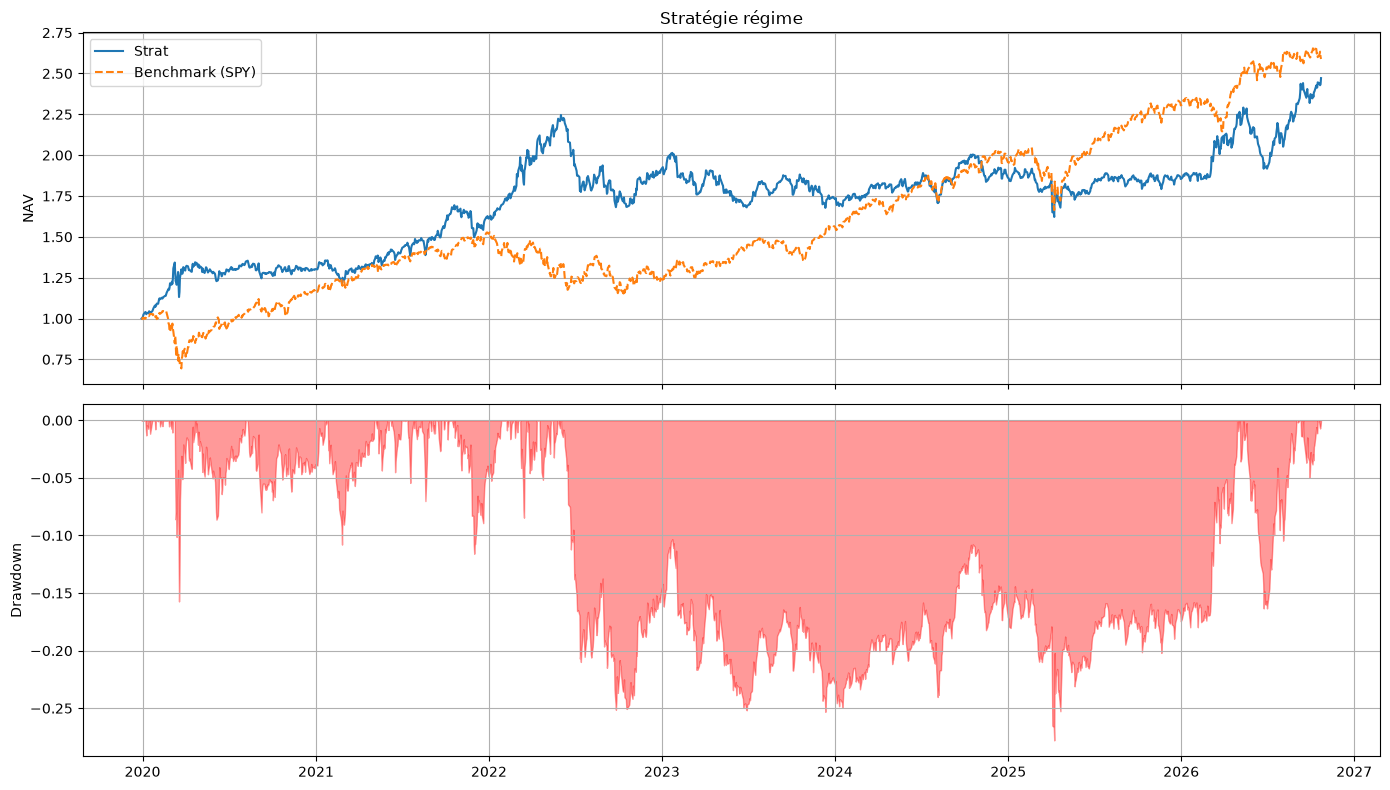

In [36]:
plot_portfolio(metrics_oos["portfolio_df"], df=OOS_df, benchmark_ticker="SPY")

## Historical portfolio performance (no tc)

In [37]:
ret_portfolio = compute_strategy_returns_df(
    df=big_df,
    allocation_rules=allocation_rules,
    start_date="2006-02-07",
    end_date=big_df.index[-1],
    tc_bps=0,
    lag=1
)

metrics = compute_allocation_metrics(
    big_df,
    allocation_rules=allocation_rules,
    start_date="2006-02-07",
    end_date=big_df.index[-1],
    freq=252,
    tc_bps=0,
    rf_daily = rf_daily,
    lag=1,
)

for k, v in metrics.items():
    if k != "portfolio_df":
        print(f"{k}: {v:.4f}")

CAGR: 0.1174
Annualized_vol: 0.1689
Sharpe: 0.6466
Sortino: 0.8530
Max_DD: -0.2782
Turnover_annualized: 23.7444


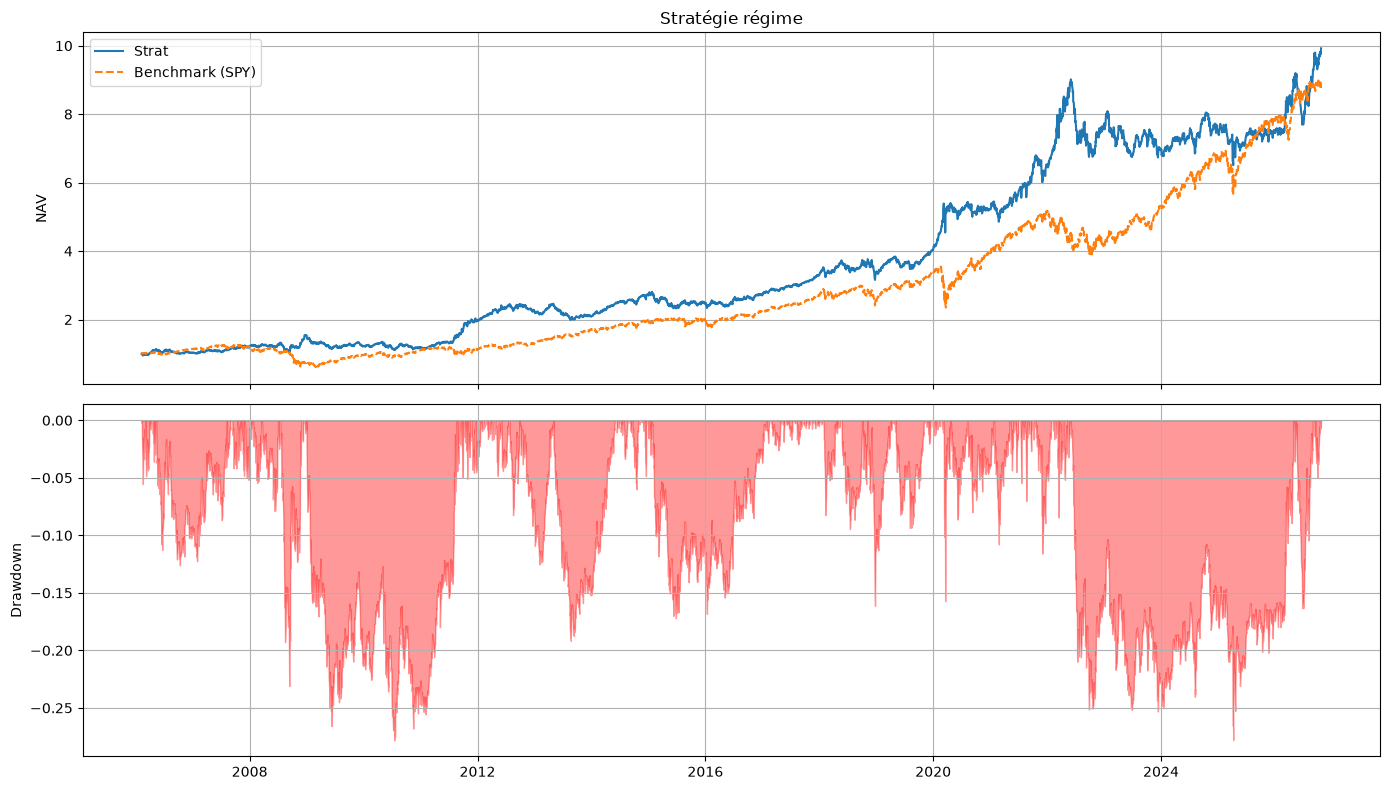

In [38]:
plot_portfolio(metrics["portfolio_df"], df=big_df, benchmark_ticker="SPY")

## Historical portfolio performance (with tc=10bps)

In [39]:
ret_portfolio_tc = compute_strategy_returns_df(
    df=big_df,
    allocation_rules=allocation_rules,
    start_date="2006-02-07",
    end_date=big_df.index[-1],
    tc_bps=tc,
    lag=1
)

metrics_tc = compute_allocation_metrics(
    big_df,
    allocation_rules=allocation_rules,
    start_date="2006-02-07",
    end_date=big_df.index[-1],
    freq=252,
    tc_bps=tc,
    rf_daily = rf_daily,
    lag=1,
)

for k, v in metrics_tc.items():
    if k != "portfolio_df":
        print(f"{k}: {v:.4f}")

CAGR: 0.0911
Annualized_vol: 0.1690
Sharpe: 0.5056
Sortino: 0.6315
Max_DD: -0.3454
Turnover_annualized: 23.7444


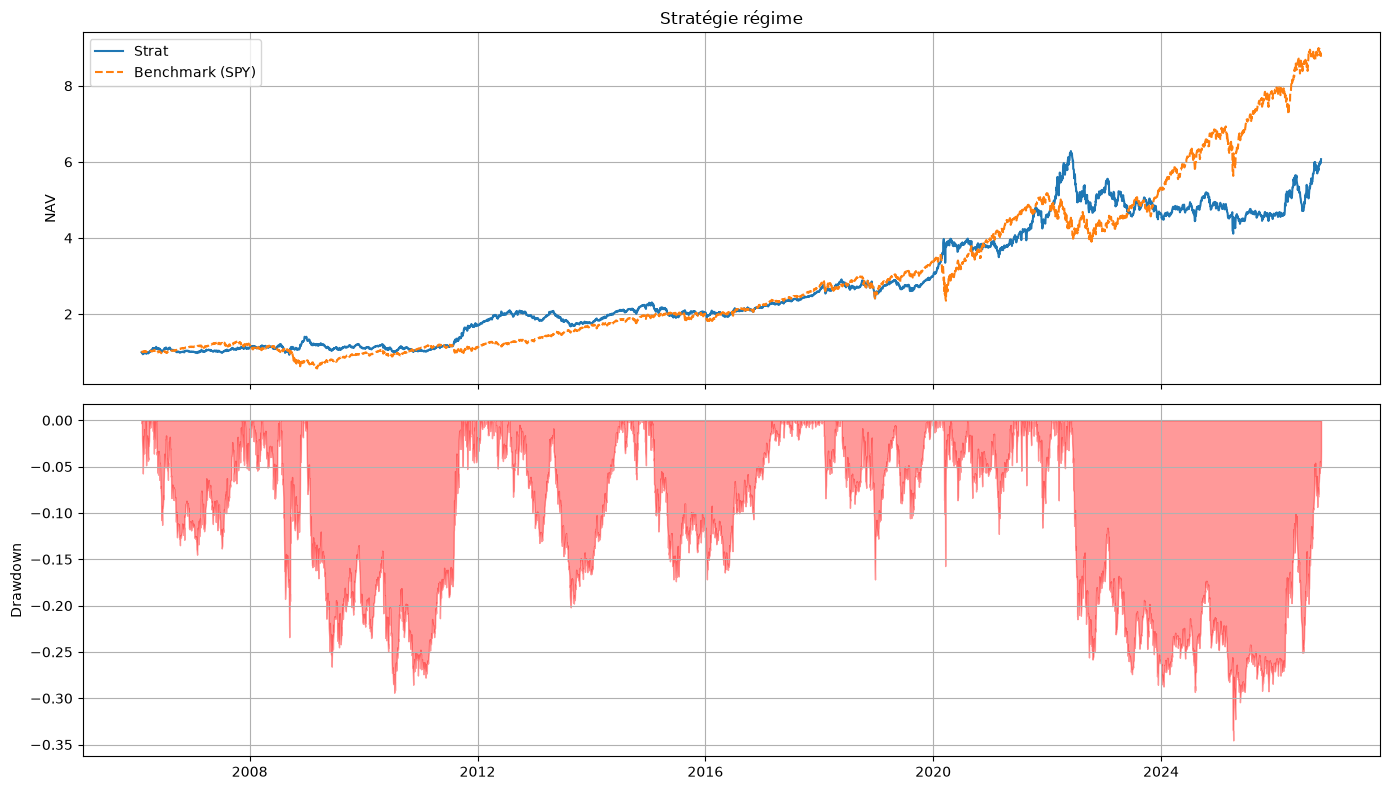

In [40]:
plot_portfolio(metrics_tc["portfolio_df"], df=big_df, benchmark_ticker="SPY")

# Conclusion

The first version of the project provides a coherent and interpretable macro regime framework linking economic
conditions to asset allocation decisions.
In gross terms, the strategy delivers performance close to SPY while significantly reducing maximum draw-
down, which suggests that the regime engine captures economically meaningful differences across market envi-
ronments.
However, the current allocation rule remains too simplistic, as it relies on binary 100% switches between
single assets and generates high turnover.
Once transaction costs are introduced, the strategy no longer outperforms SPY. Therefore, at this stage,
the model should not be viewed as an investable strategy in its current form. It should rather be interpreted as
a **promising macro regime-classification prototype** that provides a solid base for more robust portfolio-
construction and implementation work.

# Areas for Improvements

### Macro Model:

• The model should be extended to include additional macroeconomic variables in the construction of the
economic and policy scores.

• The current equal-weighting assumption should be reassessed. Future versions should investigate whether
certain variables contain more relevant information than others and should assign differentiated weights
accordingly.

• Growth is proxied by industrial production, but it could be swapped for global services production as the
SP500 mainly contains service companies.

### Portfolio Allocation:

• The portfolio-construction layer must be improved, as the current all-in, single-asset allocation rule is too
rigid and costly to implement in practice.

• Cash positions should be introduced during periods of uncertainty or when the macroeconomic signal is
weak, instead of maintaining a fully invested position at all times.

• The framework should evolve from binary regime selection toward diversified, regime-specific portfolio
weights across several assets.

• The previously conducted correlation and copula analyses should be incorporated into the allocation
framework to assess whether short positions could improve portfolio performance or risk management
under specific market conditions.

### Trading and Risk Management:

• A broader risk-management framework should be introduced, including drawdown controls, stop-loss rules,
volatility targeting, and explicit position-size constraints.

• These risk controls should be evaluated not only in terms of return enhancement, but also with respect
to their impact on portfolio survivability, turnover, and implementation realism.

• Rules should be introduced to prevent excessive rebalancing when the regime changes frequently over
short periods.

• Possible solutions include regime-persistence filters, minimum holding periods, signal buffers around regime
boundaries, and turnover constraints.